# Diabetes Risk Prediction: Modeling

**Goal:** Flag people at high risk of diabetes or prediabetes from CDC health survey answers, so they can be referred for screening.

**Data:** CDC Diabetes Health Indicators (BRFSS 2015), 253,680 respondents, 21 features. 13.9% have diabetes or prediabetes.

**Approach:**
1. Train/test split (80/20, stratified)
2. Baseline and four models: logistic regression, balanced logistic regression, random forest, LightGBM
3. 5-fold cross-validation to compare models
4. Decision threshold chosen on cross-validated predictions, evaluated once on the test set
5. Feature importance, fairness analysis by age, income and sex, and a fairness mitigation

**Final model:** LightGBM, threshold 0.50. Test ROC-AUC 0.827, recall 0.790, precision 0.307.

*For learning purposes only. Not medical advice.*

In [2]:
## 1. Setup and train/test split
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_csv("../data/diabetes_cdc.csv")

X = df.drop(columns="Diabetes_binary")  # the 21 features (inputs)
y = df["Diabetes_binary"]              # the target (what we predict)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(202944, 21) (50736, 21)
0.139 0.139


In [2]:
## 2. Baseline: always predict "no diabetes
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

baseline = DummyClassifier(strategy ="most_frequent")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, base_pred), 3))
print("Recall:", round(recall_score(y_test, base_pred), 3))


Accuracy: 0.861
Recall: 0.0


In [3]:
## 3. Logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, f1_score, roc_auc_score

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

lr_pred = logreg.predict(X_test)
lr_prob = logreg.predict_proba(X_test)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, lr_pred), 3))
print("Precision:", round(precision_score(y_test, lr_pred), 3))
print("Recall:   ", round(recall_score(y_test, lr_pred), 3))
print("F1:       ", round(f1_score(y_test, lr_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, lr_prob), 3))

Accuracy:  0.862
Precision: 0.517
Recall:    0.158
F1:        0.242
ROC-AUC:   0.819


Baseline vs. logistic regression:
- Baseline (always "no"): 86.1% accuracy but 0% recall, so it catches no diabetes cases.
- Logistic regression: 86.2% accuracy, precision 0.52, recall 0.16, F1 0.24, ROC-AUC 0.82.
- ROC-AUC of 0.82 shows the model ranks people by risk well, but the default 0.5 cutoff makes it miss 84% of diabetes cases.
- Next: use class_weight="balanced" and tune the decision threshold to raise recall.

In [4]:
## 4. Handling class imbalance: balanced class weights
logreg_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter= 1000, class_weight="balanced")
)
logreg_bal.fit(X_train, y_train)

bal_pred = logreg_bal.predict(X_test)
bal_prob = logreg_bal.predict_proba(X_test)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, bal_pred), 3))
print("Precision:", round(precision_score(y_test, bal_pred), 3))
print("Recall:   ", round(recall_score(y_test, bal_pred), 3))
print("F1:       ", round(f1_score(y_test, bal_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, bal_prob), 3))

Accuracy:  0.732
Precision: 0.311
Recall:    0.761
F1:        0.441
ROC-AUC:   0.82


In [5]:
## 5. Threshold exploration (first look)
import pandas as pd

rows = []
for t in [0.3,0.4,0.5,0.6,0.7]:
    pred_t = (bal_prob >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": round(precision_score(y_test, pred_t),3),
        "recall": round(recall_score(y_test, pred_t),3),
        "f1": round(f1_score(y_test, pred_t),3),
        "flagged_%": round(pred_t.mean()*100, 1),
    })
pd.DataFrame(rows)

,threshold,precision,recall,f1,flagged_%
0,0.3,0.238,0.917,0.378,53.6
1,0.4,0.274,0.854,0.415,43.4
2,0.5,0.311,0.761,0.441,34.1
3,0.6,0.354,0.649,0.459,25.5
4,0.7,0.400,0.498,0.444,17.3


Balanced logistic regression + threshold tuning:
- class_weight="balanced" raised recall from 0.16 to 0.76 (F1 0.24 → 0.44), with ROC-AUC unchanged at 0.82. Balancing mostly shifts probabilities upward, which is similar to lowering the cutoff.
- Thresholds trade recall against precision: 0.3 catches 92% of cases but flags 54% of people; 0.7 flags 17% but catches only 50%.
- Best F1 is at threshold 0.6 (0.459). For screening, 0.5–0.6 is a reasonable balance; the right choice depends on clinic capacity and the cost of missed cases.
- Caveat: threshold was chosen on the test set; it should be tuned on a validation set (to do with cross-validation).

In [6]:
## 6. Random forest
from sklearn.ensemble import RandomForestClassifier

rf= RandomForestClassifier(
    n_estimators = 100,
    min_samples_leaf= 50,
    class_weight = "balanced",
    n_jobs = -1,
    random_state = 42
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall:   ", round(recall_score(y_test, rf_pred), 3))
print("F1:       ", round(f1_score(y_test, rf_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, rf_prob), 3))


Accuracy:  0.722
Precision: 0.306
Recall:    0.785
F1:        0.44
ROC-AUC:   0.824


Random forest (100 trees, min_samples_leaf=50, balanced):
- ROC-AUC 0.824, recall 0.785, precision 0.306, F1 0.440.
- Essentially a tie with balanced logistic regression (ROC-AUC 0.820, F1 0.441).
- Suggests the features carry limited non-linear signal; survey data may cap performance around 0.82–0.83 ROC-AUC.
- When performance is equal, logistic regression is preferable: faster, simpler and interpretable.
- Next: test gradient boosting (LightGBM) to confirm the ceiling.
    

In [7]:
## 7. LightGBM (gradient boosting)
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbose=-1,
)
lgbm.fit(X_train, y_train)

lgbm_pred = lgbm.predict(X_test)
lgbm_prob = lgbm.predict_proba(X_test)[:, 1]

print("Accuracy: ", round(accuracy_score(y_test, lgbm_pred), 3))
print("Precision:", round(precision_score(y_test, lgbm_pred), 3))
print("Recall:   ", round(recall_score(y_test, lgbm_pred), 3))
print("F1:       ", round(f1_score(y_test, lgbm_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, lgbm_prob), 3))

Accuracy:  0.722
Precision: 0.307
Recall:    0.79
F1:        0.442
ROC-AUC:   0.827


In [8]:
## 8. Cross-validated model comparison
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic regression": logreg_bal,
    "Random forest": rf,
    "LightGBM": lgbm,
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    print(f"{name:20s} ROC-AUC: {scores.mean():.3f} ± {scores.std():.3f}")

Logistic regression  ROC-AUC: 0.823 ± 0.001
Random forest        ROC-AUC: 0.828 ± 0.002
LightGBM             ROC-AUC: 0.830 ± 0.002


LightGBM and 5-fold cross-validation:
- LightGBM (300 trees, learning rate 0.05, balanced) on the test set: ROC-AUC 0.827, recall 0.790, precision 0.307, F1 0.442.
- 5-fold cross-validated ROC-AUC on the training set:
  - Logistic regression: 0.823 ± 0.001
  - Random forest: 0.828 ± 0.002
  - LightGBM: 0.830 ± 0.002
- Scores are very stable across folds. LightGBM's small lead is consistent, so it is chosen as the final model.
- All three model families fall within 0.82–0.83, suggesting the self-reported survey features cap performance more than the choice of algorithm.

In [9]:
## 9. Choosing the threshold with cross-validation
from sklearn.model_selection import cross_val_predict
import numpy as np

# Honest probabilities for every training person
train_prob = cross_val_predict(
    lgbm, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

# Try many thresholds, keep the scores for each
rows = []
for t in np.arange(0.30, 0.81, 0.05):
    p = (train_prob >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": round(precision_score(y_train, p), 3),
        "recall":    round(recall_score(y_train, p), 3),
        "f1":        round(f1_score(y_train, p), 3),
    })

thr_table = pd.DataFrame(rows)
best = thr_table.loc[thr_table["f1"].idxmax()]
print("Best threshold by F1:", best["threshold"])
thr_table

Best threshold by F1: 0.65


,threshold,precision,recall,f1
0,0.30,0.243,0.920,0.385
1,0.35,0.258,0.896,0.401
2,0.40,0.273,0.866,0.415
3,0.45,0.290,0.832,0.430
4,0.50,0.309,0.791,0.444
5,0.55,0.331,0.744,0.458
6,0.60,0.354,0.685,0.467
7,0.65,0.381,0.618,0.472
8,0.70,0.414,0.535,0.467
9,0.75,0.454,0.433,0.443


In [10]:
## 10. Final evaluation on the test set

from sklearn.metrics import confusion_matrix

for t in [0.50, 0.65]:
    test_pred = (lgbm_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

    print(f"--- Threshold {t} ---")
    print("Precision:", round(precision_score(y_test, test_pred), 3))
    print("Recall:   ", round(recall_score(y_test, test_pred), 3))
    print("F1:       ", round(f1_score(y_test, test_pred), 3))
    print(f"Caught {tp:,} of {tp + fn:,} diabetes cases | {fp:,} false alarms | {fn:,} missed")
    print()

print("ROC-AUC:", round(roc_auc_score(y_test, lgbm_prob), 3))

--- Threshold 0.5 ---
Precision: 0.307
Recall:    0.79
F1:        0.442
Caught 5,585 of 7,069 diabetes cases | 12,615 false alarms | 1,484 missed

--- Threshold 0.65 ---
Precision: 0.378
Recall:    0.614
F1:        0.468
Caught 4,337 of 7,069 diabetes cases | 7,123 false alarms | 2,732 missed

ROC-AUC: 0.827


Final threshold selection and test-set evaluation:
- Threshold chosen on cross-validated training predictions only (test set untouched).
- 0.65 maximizes F1 (0.472), but for screening, recall matters more, so 0.50 was chosen to catch ~80% of cases.
- Final test results (LightGBM, threshold 0.50): recall 0.790, precision 0.307, F1 0.442, ROC-AUC 0.827.
  Caught 5,585 of 7,069 diabetes cases; 1,484 missed; 12,615 false alarms.
- Test results closely match cross-validated estimates (recall 0.791 vs 0.790), so the model generalizes well.
- Moving from 0.65 to 0.50 catches 1,248 more cases at the cost of 5,492 more false alarms (~4.4 extra screenings per extra case found).
- 

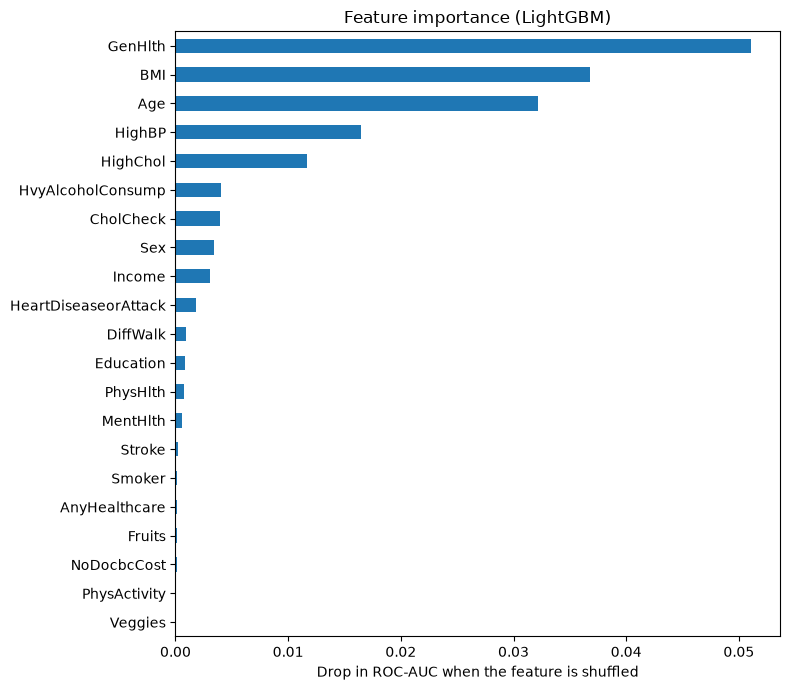

GenHlth                 0.0511
BMI                     0.0368
Age                     0.0322
HighBP                  0.0165
HighChol                0.0117
HvyAlcoholConsump       0.0040
CholCheck               0.0040
Sex                     0.0034
Income                  0.0031
HeartDiseaseorAttack    0.0018
DiffWalk                0.0009
Education               0.0008
PhysHlth                0.0008
MentHlth                0.0006
Stroke                  0.0003
Smoker                  0.0002
AnyHealthcare           0.0001
Fruits                  0.0001
NoDocbcCost             0.0001
PhysActivity            0.0001
Veggies                 0.0000
dtype: float64

In [11]:
## 11. Feature importance
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    lgbm, X_test, y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 7))
plt.title("Feature importance (LightGBM)")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4)

Feature importance (permutation importance on test set, ROC-AUC drop):
- Top 5: GenHlth (0.051), BMI (0.037), Age (0.032), HighBP (0.017), HighChol (0.012). Remaining features add very little.
- Matches exploration: self-rated health, BMI and age showed the strongest patterns.
- HeartDiseaseorAttack, DiffWalk and Stroke had large raw differences in diabetes rate but low importance here, likely because their information overlaps with GenHlth and Age.
- HvyAlcoholConsump ranks 6th: the model uses the pattern even though it likely reflects reverse causation, not a protective effect.
- Caveat: correlated features share credit, so low importance means "redundant given other features," not "unrelated to diabetes."

In [12]:
## 12. Fairness analysis
results = X_test.copy()
results["y_true"] = y_test.values
results["y_pred"] = (lgbm_prob >= 0.50).astype(int)
results["prob"] = lgbm_prob

def group_report(col):
    rows = []
    for group, sub in results.groupby(col):
        rows.append({
            col: group,
            "people": len(sub),
            "diabetes_rate": round(sub["y_true"].mean(), 3),
            "recall": round(recall_score(sub["y_true"], sub["y_pred"], zero_division=0), 3),
            "precision": round(precision_score(sub["y_true"], sub["y_pred"], zero_division=0), 3),
            "flagged_%": round(sub["y_pred"].mean() * 100, 1),
        })
    return pd.DataFrame(rows)

group_report("Age")


,Age,people,diabetes_rate,recall,precision,flagged_%
0,1,1207,0.012,0.071,0.250,0.3
1,2,1525,0.019,0.379,0.344,2.1
2,3,2242,0.027,0.333,0.253,3.5
3,4,2775,0.056,0.445,0.337,7.4
4,5,3213,0.063,0.567,0.232,15.3
5,6,3887,0.085,0.653,0.266,20.9
6,7,5206,0.116,0.706,0.299,27.4
7,8,6055,0.134,0.777,0.302,34.5
8,9,6707,0.178,0.841,0.335,44.6
9,10,6515,0.202,0.848,0.333,51.7


In [13]:
group_report("Income")


,Income,people,diabetes_rate,recall,precision,flagged_%
0,1,1941,0.245,0.886,0.369,58.8
1,2,2325,0.271,0.908,0.377,65.3
2,3,3162,0.223,0.897,0.339,59.1
3,4,3990,0.195,0.868,0.317,53.4
4,5,5174,0.172,0.835,0.302,47.6
5,6,7281,0.142,0.795,0.290,39.0
6,7,8730,0.124,0.736,0.287,31.9
7,8,18133,0.081,0.625,0.266,19.1


In [14]:
group_report("Sex")

,Sex,people,diabetes_rate,recall,precision,flagged_%
0,0,28531,0.129,0.777,0.308,32.6
1,1,22205,0.152,0.804,0.306,40.1


Fairness check (test set, threshold 0.50):
- Age: recall rises from ~7% (18–24, small sample) and 33–45% (25–39) to 78–86% (55+). Young adults with diabetes are frequently missed.
- Income: recall falls from ~90% (under $15k) to 63% ($75k+), the largest income group (36% of test set).
- Sex: similar performance (recall 0.78 female vs 0.80 male; precision ~0.31 for both).
- Precision is fairly stable across groups (~0.25–0.38); the gaps are in who gets caught.
- Pattern: recall tracks each group's diabetes rate. The model relies on group-level risk (age, income), so people who don't fit the typical profile are under-detected.
- Possible mitigations: group-specific thresholds (more false alarms), richer clinical features, and clearly documenting this limitation.



In [15]:
## 13. Fairness mitigation: lower threshold for under-40s
young_train = (X_train["Age"] <= 4).values
yt_young = y_train.values[young_train]
prob_young = train_prob[young_train]

rows = []
for t in [0.50, 0.40, 0.30, 0.25, 0.20, 0.15]:
    p = (prob_young >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall": round(recall_score(yt_young, p), 3),
        "precision": round(precision_score(yt_young, p, zero_division=0), 3),
        "flagged_%": round(p.mean() * 100, 1),
    })

pd.DataFrame(rows)

,threshold,recall,precision,flagged_%
0,0.50,0.334,0.241,4.1
1,0.40,0.419,0.200,6.2
2,0.30,0.546,0.163,9.9
3,0.25,0.603,0.141,12.6
4,0.20,0.667,0.122,16.2
5,0.15,0.739,0.102,21.4


In [16]:
##Testing the chosen threshold (0.20 for under-40s, 0.50 for everyone else) on the test set:
young_test = (X_test["Age"] <= 4).values

single_pred = (lgbm_prob >= 0.50).astype(int)
thr = np.where(young_test, 0.20, 0.50)
fair_pred = (lgbm_prob >= thr).astype(int)

def summarize(name, pred, mask):
    yt = y_test.values[mask]
    p = pred[mask]
    tp = ((p == 1) & (yt == 1)).sum()
    fp = ((p == 1) & (yt == 0)).sum()
    print(f"{name:28s} recall {recall_score(yt, p):.3f} | precision {precision_score(yt, p):.3f} | caught {tp:,} | false alarms {fp:,}")

all_people = np.ones(len(y_test), dtype=bool)

print("UNDER 40")
summarize("Single threshold (0.50)", single_pred, young_test)
summarize("Fair thresholds (0.20/0.50)", fair_pred, young_test)
print("\nEVERYONE")
summarize("Single threshold (0.50)", single_pred, all_people)
summarize("Fair thresholds (0.20/0.50)", fair_pred, all_people)

UNDER 40
Single threshold (0.50)      recall 0.391 | precision 0.316 | caught 101 | false alarms 219
Fair thresholds (0.20/0.50)  recall 0.643 | precision 0.133 | caught 166 | false alarms 1,085

EVERYONE
Single threshold (0.50)      recall 0.790 | precision 0.307 | caught 5,585 | false alarms 12,615
Fair thresholds (0.20/0.50)  recall 0.799 | precision 0.295 | caught 5,650 | false alarms 13,481



Fairness mitigation: lower threshold for under-40s:
- Under-40 threshold chosen on cross-validated training predictions: 0.20 (vs 0.50 for 40+), prioritizing detection of young diabetics.
- Test set, under 40: recall 0.391 → 0.643; caught 101 → 166 of ~258 cases (+65); false alarms 219 → 1,085 (+866).
- Test set, everyone: recall 0.790 → 0.799; precision 0.307 → 0.295; false alarms +7%.
- Trade-off: ~13 extra screenings per additional young case caught (vs ~4–5 overall). Whether this is worth it is a policy decision.
- Group-specific thresholds narrow but don't close the gap; the underlying limitation is that survey features carry weak signal for young adults.

## Summary

- **Accuracy is misleading here:** always predicting "no" scores 86% accuracy with 0% recall.
- **All model families plateau at ROC-AUC 0.82–0.83** (cross-validated). The self-reported survey features, not the algorithm, limit performance.
- **Final model:** LightGBM at threshold 0.50 catches 79% of diabetes cases on unseen data (5,585 of 7,069), with ~2.3 false alarms per case caught.
- **Top features:** self-rated general health, BMI, age, high blood pressure, high cholesterol.
- **Fairness:** recall is much lower for adults under 40 (39%) and the highest income group (63%). A lower threshold (0.20) for under-40s raises their recall to 64%, at ~13 extra screenings per additional case found.